# Phase 5 — Model comparison, validation-only selection, and the single held-out test evaluation
Everything here is read from `artifacts/reports/*`. All models are scored with the **same** implementation (`src/evaluate.py`), corpus
(5,183 docs), queries and retrieval depth. The test numbers exist only after `scripts/evaluate_models.py --stage test`.

In [1]:
import sys
from pathlib import Path
import pandas as pd, matplotlib.pyplot as plt
root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "configs" / "base.yaml").is_file())
sys.path.insert(0, str(root))
from src.config import load_config
from src.utils import read_json
cfg = load_config(["configs/baseline.yaml", "configs/compare.yaml"], root=root)
R = cfg["_abs"]["reports_dir"]
def maybe(name): p = R / name; return read_json(p) if p.is_file() else None
VAL, SEL, TEST = maybe("model_comparison_val.json"), maybe("model_selection.json"), maybe("test_results.json")
print("validation stage:", VAL["status"] if VAL else "NOT RUN (python scripts/evaluate_models.py --stage validation)")
print("selection       :", (SEL["status"] + " -> " + SEL["selected"]) if SEL else "-")
print("test stage      :", TEST["status"] if TEST else "NOT RUN (python scripts/evaluate_models.py --stage test --confirm-single-test-evaluation)")

validation stage: PASS
selection       : FROZEN -> ft_hardneg_dense
test stage      : PASS


## 1. Validation comparison (162 queries; same metric code for every model)

In [2]:
if VAL:
    cols = ["ndcg@10", "recall@1", "recall@5", "recall@10", "mrr@10", "map@10", "precision@10"]
    df = pd.DataFrame({k: {c: v["metrics"][c] for c in cols} for k, v in VAL["models"].items()}).T
    df["ndcg@10 95% CI"] = [f"[{v['bootstrap_ci']['ndcg@10']['ci_low']:.4f}, {v['bootstrap_ci']['ndcg@10']['ci_high']:.4f}]" for v in VAL["models"].values()]
    display(df.round(4)); print(VAL["eval_setup"]["n_queries"], "queries,", VAL["eval_setup"]["n_judgments"], "judgments, corpus", VAL["eval_setup"]["candidate_corpus_size"], ", top_k", VAL["eval_setup"]["retrieval_top_k"])

,ndcg@10,recall@1,recall@5,recall@10,mrr@10,map@10,precision@10,ndcg@10 95% CI
baseline,0.6816,0.5329,0.7634,0.7932,0.6536,0.6398,0.0852,"[0.6208, 0.7404]"
ft_hardneg_dense,0.7433,0.6183,0.8117,0.8323,0.7174,0.7110,0.0901,"[0.6830, 0.7994]"
ft_pos_only,0.6974,0.5360,0.7973,0.8364,0.6584,0.6481,0.0901,"[0.6381, 0.7535]"


162 queries, 177 judgments, corpus 5183 , top_k 100


## 2. Paired differences (A minus B) with bootstrap CIs — negative changes are valid results

In [3]:
if VAL:
    rows = []
    for name, comp in VAL["paired_comparisons"].items():
        for m, c in comp.items():
            rows.append({"comparison": name, "metric": m, "mean_diff": c["mean_diff"], "ci_low": c["ci_low"], "ci_high": c["ci_high"],
                         "CI excludes 0": c["ci_excludes_zero"], "better/tied/worse": f"{c['queries_better']}/{c['queries_tied']}/{c['queries_worse']}"})
    display(pd.DataFrame(rows).round(4))

,comparison,metric,mean_diff,ci_low,ci_high,CI excludes 0,better/tied/worse
0,ft_hardneg_dense__minus__baseline,mrr@10,0.0639,0.0193,0.1105,True,34/110/18
1,ft_hardneg_dense__minus__baseline,ndcg@10,0.0616,0.0205,0.1043,True,39/106/17
2,ft_hardneg_dense__minus__baseline,recall@1,0.0854,0.0206,0.1502,True,23/130/9
3,ft_hardneg_dense__minus__baseline,recall@10,0.0391,-0.0093,0.0895,False,14/142/6
4,ft_hardneg_dense__minus__ft_pos_only,mrr@10,0.0590,0.0175,0.1026,True,33/113/16
5,ft_hardneg_dense__minus__ft_pos_only,ndcg@10,0.0458,0.0101,0.0828,True,38/107/17
6,ft_hardneg_dense__minus__ft_pos_only,recall@1,0.0823,0.0206,0.1461,True,21/134/7
7,ft_hardneg_dense__minus__ft_pos_only,recall@10,-0.0041,-0.0432,0.0340,False,7/148/7
8,ft_pos_only__minus__baseline,mrr@10,0.0048,-0.0296,0.0405,False,16/124/22
9,ft_pos_only__minus__baseline,ndcg@10,0.0158,-0.0154,0.0490,False,19/118/25


## 3. Selection and freeze

In [4]:
if SEL:
    print("rule:", SEL["rule"]); print("scores:", {k: round(v, 4) for k, v in SEL["selection_scores"].items()}); print("SELECTED:", SEL["selected"], "| status:", SEL["status"])
    print("fingerprint:", SEL["fingerprint"]); print("test candidates:", SEL["test_candidates"])
    display(pd.DataFrame({k: {"weights_sha256": v["weights_sha256"][:16] + "…", "embeddings_sha256": v["embeddings_sha256"][:16] + "…", "index_sha256": v["index_sha256"][:16] + "…"} for k, v in SEL["candidates"].items()}).T)

rule: {'metric': 'ndcg@10', 'rule': 'argmax_point_estimate', 'split': 'val', 'tie_break_order': ['baseline', 'ft_pos_only', 'ft_hardneg_dense']}
scores: {'baseline': 0.6816, 'ft_hardneg_dense': 0.7433, 'ft_pos_only': 0.6974}
SELECTED: ft_hardneg_dense | status: FROZEN
fingerprint: d8e886cb5d080d5f34aba4111ca73d4546160191666e4cfb5fa9893e949ad0db
test candidates: ['ft_hardneg_dense', 'baseline']


,weights_sha256,embeddings_sha256,index_sha256
baseline,53aa51172d142c89…,3feadf339a3a1e1e…,15bdc70107a95bf9…
ft_hardneg_dense,405b247000543b91…,9f8a173c943a3108…,97fa0483c7d0b4ea…
ft_pos_only,981fbdeb06013fd8…,ba85aa0c2af7a89b…,9e48aeb77ea6174f…


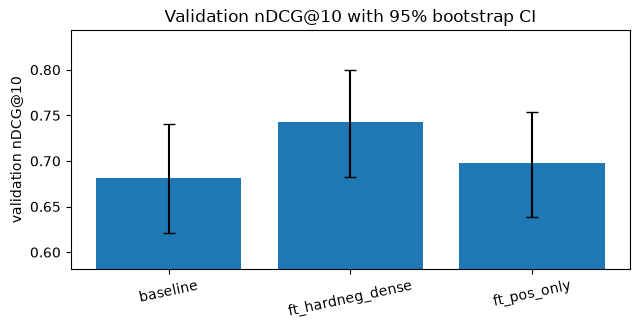

In [5]:
if VAL:
    fig, ax = plt.subplots(figsize=(6.5, 3.4)); names = list(VAL["models"])
    m = [VAL["models"][k]["metrics"]["ndcg@10"] for k in names]
    err = [[VAL["models"][k]["metrics"]["ndcg@10"] - VAL["models"][k]["bootstrap_ci"]["ndcg@10"]["ci_low"] for k in names],
           [VAL["models"][k]["bootstrap_ci"]["ndcg@10"]["ci_high"] - VAL["models"][k]["metrics"]["ndcg@10"] for k in names]]
    ax.bar(names, m, yerr=err, capsize=4); ax.set(ylabel="validation nDCG@10", title="Validation nDCG@10 with 95% bootstrap CI", ylim=(max(0, min(m) - 0.1), min(1, max(m) + 0.1)))
    plt.xticks(rotation=12); plt.tight_layout(); plt.show()

## 4. Resource usage (measured on validation queries, CPU)

In [6]:
if VAL:
    rows = {}
    for k, v in VAL["models"].items():
        lat = v["latency_single_query"]
        rows[k] = {"encode corpus (s)": v["timing_s"]["encode_corpus"], "corpus cache reused": v["assets"]["cache_used"],
                   "query encode p50 (ms)": lat["encode_ms"]["p50"], "FAISS search p50 (ms)": lat["faiss_search_ms"]["p50"], "peak RSS (MB)": v["peak_rss_mb"]}
    display(pd.DataFrame(rows).T.round(2))
    sizes = {p.name: round(p.stat().st_size / 1e6, 2) for p in sorted((root / "artifacts" / "indexes").glob("*.faiss"))}; print("index sizes (MB):", sizes)

,encode corpus (s),corpus cache reused,query encode p50 (ms),FAISS search p50 (ms),peak RSS (MB)
baseline,0.0,True,13.6231,0.9085,657.5
ft_hardneg_dense,280.136369,False,13.1194,0.8333,367.9
ft_pos_only,276.051993,False,15.8525,0.9732,396.0


index sizes (MB): {'baseline_flatip.faiss': 7.96, 'ft_hardneg_dense_flatip.faiss': 7.96, 'ft_pos_only_flatip.faiss': 7.96}


## 5. Where do the best positives rank?

In [7]:
if VAL: display(pd.DataFrame({k: v["best_positive_rank_buckets"] for k, v in VAL["models"].items()}).T)

,not in top 100,rank 1,rank 11-100,rank 2-10
baseline,9,90,23,40
ft_hardneg_dense,4,104,21,33
ft_pos_only,7,90,19,46


## 6. Held-out test (frozen model + baseline, evaluated once)

In [8]:
if TEST:
    cols = ["ndcg@10", "recall@1", "recall@5", "recall@10", "mrr@10", "map@10", "precision@10"]
    df = pd.DataFrame({k: {c: v["test_metrics"][c] for c in cols} for k, v in TEST["models"].items()}).T
    df["ndcg@10 95% CI"] = [f"[{v['test_bootstrap_ci']['ndcg@10']['ci_low']:.4f}, {v['test_bootstrap_ci']['ndcg@10']['ci_high']:.4f}]" for v in TEST["models"].values()]
    display(df.round(4)); print(TEST["eval_setup"]["n_queries"], "queries,", TEST["eval_setup"]["n_judgments"], "judgments; selected:", TEST["selected_model"])
    display(pd.DataFrame({k: v["validation_to_test_change"] for k, v in TEST["models"].items()}).T.round(4))
    if TEST["paired_selected_minus_baseline"]:
        display(pd.DataFrame(TEST["paired_selected_minus_baseline"]).T[["mean_diff", "ci_low", "ci_high", "ci_excludes_zero", "queries_better", "queries_tied", "queries_worse"]].round(4))

,ndcg@10,recall@1,recall@5,recall@10,mrr@10,map@10,precision@10,ndcg@10 95% CI
baseline,0.6451,0.4823,0.7379,0.7833,0.6047,0.5959,0.0883,"[0.6010, 0.6900]"
ft_hardneg_dense,0.7131,0.5782,0.7743,0.8277,0.6815,0.6724,0.0927,"[0.6694, 0.7567]"


300 queries, 339 judgments; selected: ft_hardneg_dense


,map@10,mrr@10,ndcg@10,precision@10,recall@1,recall@10,recall@5
baseline,-0.0439,-0.0488,-0.0365,0.0031,-0.0506,-0.0099,-0.0254
ft_hardneg_dense,-0.0386,-0.0359,-0.0302,0.0025,-0.0401,-0.0046,-0.0374


,mean_diff,ci_low,ci_high,ci_excludes_zero,queries_better,queries_tied,queries_worse
mrr@10,0.076784,0.046391,0.107847,True,67,206,27
ndcg@10,0.068012,0.040394,0.09624,True,74,197,29
recall@1,0.095833,0.055833,0.1375,True,38,254,8
recall@10,0.044333,0.011,0.078667,True,23,267,10


## 7. Failure cases (descriptive; the model is frozen — nothing is tuned after reading these)

In [9]:
for name in ([f"val_failure_cases_{SEL['selected']}.md"] if SEL else []) + ([f"test_failure_cases_{SEL['selected']}.md"] if TEST and SEL else []):
    p = R / name
    if p.is_file(): print("-----", name); print("\n".join(p.read_text(encoding="utf-8").splitlines()[:30])); print()

----- val_failure_cases_ft_hardneg_dense.md
# Validation failure cases: ft_hardneg_dense

> Validation split: model-selection data (not the held-out test).

> Retrieved documents that are not judged positives may still be relevant (qrels are sparse).

**Best-positive rank distribution — ft_hardneg_dense:** {'rank 1': 104, 'rank 2-10': 33, 'rank 11-100': 21, 'not in top 100': 4}

**Best-positive rank distribution — baseline:** {'rank 1': 90, 'rank 2-10': 40, 'rank 11-100': 23, 'not in top 100': 9}

## No judged positive in the top 10 (25 of 162 queries; showing 8)

### Query 0
**Claim:** 0-dimensional biomaterials lack inductive properties.

**Judged positive(s):** [31715818] New opportunities: the use of nanotechnologies to manipulate and track stem cells.
- best-positive rank: ft_hardneg_dense=16, baseline=4  |  nDCG@10: ft_hardneg_dense=0.000, baseline=0.431
- ft_hardneg_dense #1 (cos 0.313): [29638116] Complex Tissue and Disease Modeling using hiPSCs.
- ft_hardneg_dense #2 (cos 0.30

## 8. Limitations
- Judgments are sparse and positive-only; a retrieved but unjudged paper may be relevant, so scores are relative to known positives.
- SciFact is a shared-corpus benchmark (all splits search the same 5,183 papers); one training seed per model; small query sets (162 val / 300 test).
- Fine-tuned models' epoch was chosen on validation inside Phase 4, so their validation scores are optimistic; the test split is the unbiased read.
- Latency/memory are from one CPU machine and are not portable benchmarks.